# Neural Network House Price Prediction: Regression Modeling, Benchmarking, and Error Diagnostics

**Project objective:** Build, evaluate, and explain a neural-network regression model that predicts house prices from structured property features: `size`, `location_score`, and `bedrooms`.

**Key result:** The neural network achieved a test **MAE of $11,565.78**, **RMSE of $13,940.08**, and **R² of 0.961** after converting predictions back from the scaled target into real dollar terms.

**Project framing:** This is a strong supporting machine-learning project. Its value is not that a neural network automatically beats every simpler model. Its value is that the model is evaluated honestly, compared against practical baselines, and explained through diagnostics and feature importance.


## 1. Packages and Reproducibility

This cell imports the core data, modeling, neural-network, and visualization libraries used in the project. It also sets random seeds for Python, NumPy, and TensorFlow so the workflow is as reproducible as possible across runs.

The notebook uses TensorFlow/Keras for the neural network and scikit-learn for preprocessing, baselines, metrics, and model interpretation.


In [2]:
from pathlib import Path
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Save visuals to the project-level images folder.
# This assumes the notebook is inside a notebook/notebooks folder,
# and the images folder is one level above it.

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() in {"notebook", "notebooks"}:
    IMAGES_DIR = CURRENT_DIR.parent / "images"
else:
    IMAGES_DIR = CURRENT_DIR / "images"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Working directory: {CURRENT_DIR.resolve()}")
print(f"Saving images to: {IMAGES_DIR.resolve()}")

COLORS = {
    "blue": "#38BDF8",
    "teal": "#34D399",
    "purple": "#A78BFA",
    "gold": "#FBBF24",
    "orange": "#F59E0B",
    "slate": "#64748B",
    "gray": "#94A3B8",
    "green": "#10B981",
    "pink": "#FB7185",
    "dark": "#0F172A"
}


def currency_k(x, pos=None):
    """
    Format values as currency in thousands for Matplotlib axes.
    Escaped dollar signs prevent Matplotlib from treating text between $ symbols as math text.
    """
    value = x / 1000

    if value < 0:
        return f"-\\${abs(value):,.0f}K"

    return f"\\${value:,.0f}K"


def currency_full(x):
    """
    Format full dollar values for Matplotlib labels and annotations.
    """
    if x < 0:
        return f"-\\${abs(x):,.0f}"

    return f"\\${x:,.0f}"


def currency_full_plain(x):
    """
    Format full dollar values for normal print output.
    This version does not include escape characters.
    """
    if x < 0:
        return f"-${abs(x):,.0f}"

    return f"${x:,.0f}"


def save_figure(fig, filename):
    output_path = IMAGES_DIR / filename
    fig.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure to {output_path.resolve()}")

Working directory: D:\Intro_to_DL_BTL\house-price-prediction-main\notebooks
Saving images to: D:\Intro_to_DL_BTL\house-price-prediction-main\images


## 2. Data Loading and Validation

This section loads the housing dataset and validates the expected schema before modeling. The project uses four columns:

- `size`: property size
- `location_score`: numeric location-quality score
- `bedrooms`: number of bedrooms
- `price`: target variable to predict

The validation step is important because it prevents the notebook from silently training on missing, renamed, or incorrectly structured data.


In [3]:
# Load dataset.
# This keeps the original project structure, but also works if the notebook is run from the same folder as the CSV.

candidate_paths = [
    Path("../data/housing_prices.csv"),
    Path("housing_prices.csv"),
    Path("/mnt/data/housing_prices.csv")
]

data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("housing_prices.csv was not found. Place it in ../data/ or the notebook folder.")

data = pd.read_csv(data_path)

expected_columns = ["size", "location_score", "bedrooms", "price"]
missing_columns = [col for col in expected_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

data = data[expected_columns].copy()

print(f"Dataset shape: {data.shape}")
display(data.head())

Dataset shape: (1000, 4)


,size,location_score,bedrooms,price
0,1360,2,5,486545
1,4272,3,2,605497
2,3592,1,4,552767
3,966,9,3,528057
4,4926,8,4,713217


In [4]:
# Basic data quality checks

quality_summary = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_values": data.isna().sum(),
    "unique_values": data.nunique(),
    "min": data.min(numeric_only=True),
    "max": data.max(numeric_only=True)
})

display(quality_summary)
print(f"Duplicate rows: {data.duplicated().sum()}")

,dtype,missing_values,unique_values,min,max
size,int64,0,894,503,4999
location_score,int64,0,9,1,9
bedrooms,int64,0,5,1,5
price,int64,0,998,379753,753781


Duplicate rows: 0


### Data Quality Findings

The dataset contains **1,000 rows** and **4 columns**, with no missing values and no duplicate rows. The features are clean and ready for modeling:

- `size` ranges from **503** to **4,999**
- `location_score` ranges from **1** to **9**
- `bedrooms` ranges from **1** to **5**
- `price` ranges from **$379,753** to **$753,781**

This makes the project suitable for a clean regression workflow, but the small number of predictors also means the neural network should be compared carefully against simpler baselines.


## 3. Exploratory Data Analysis

Before training the neural network, this section examines the target distribution and the relationship between each feature and house price.

This matters for this project because it shows that the model is not treated as a black box. The EDA helps answer three practical questions:

1. What does the target variable look like?
2. Which features appear most related to price?
3. Does the dataset support a complex model, or would a simpler model be competitive?


Saved figure to D:\Intro_to_DL_BTL\house-price-prediction-main\images\house_price_data_story.png


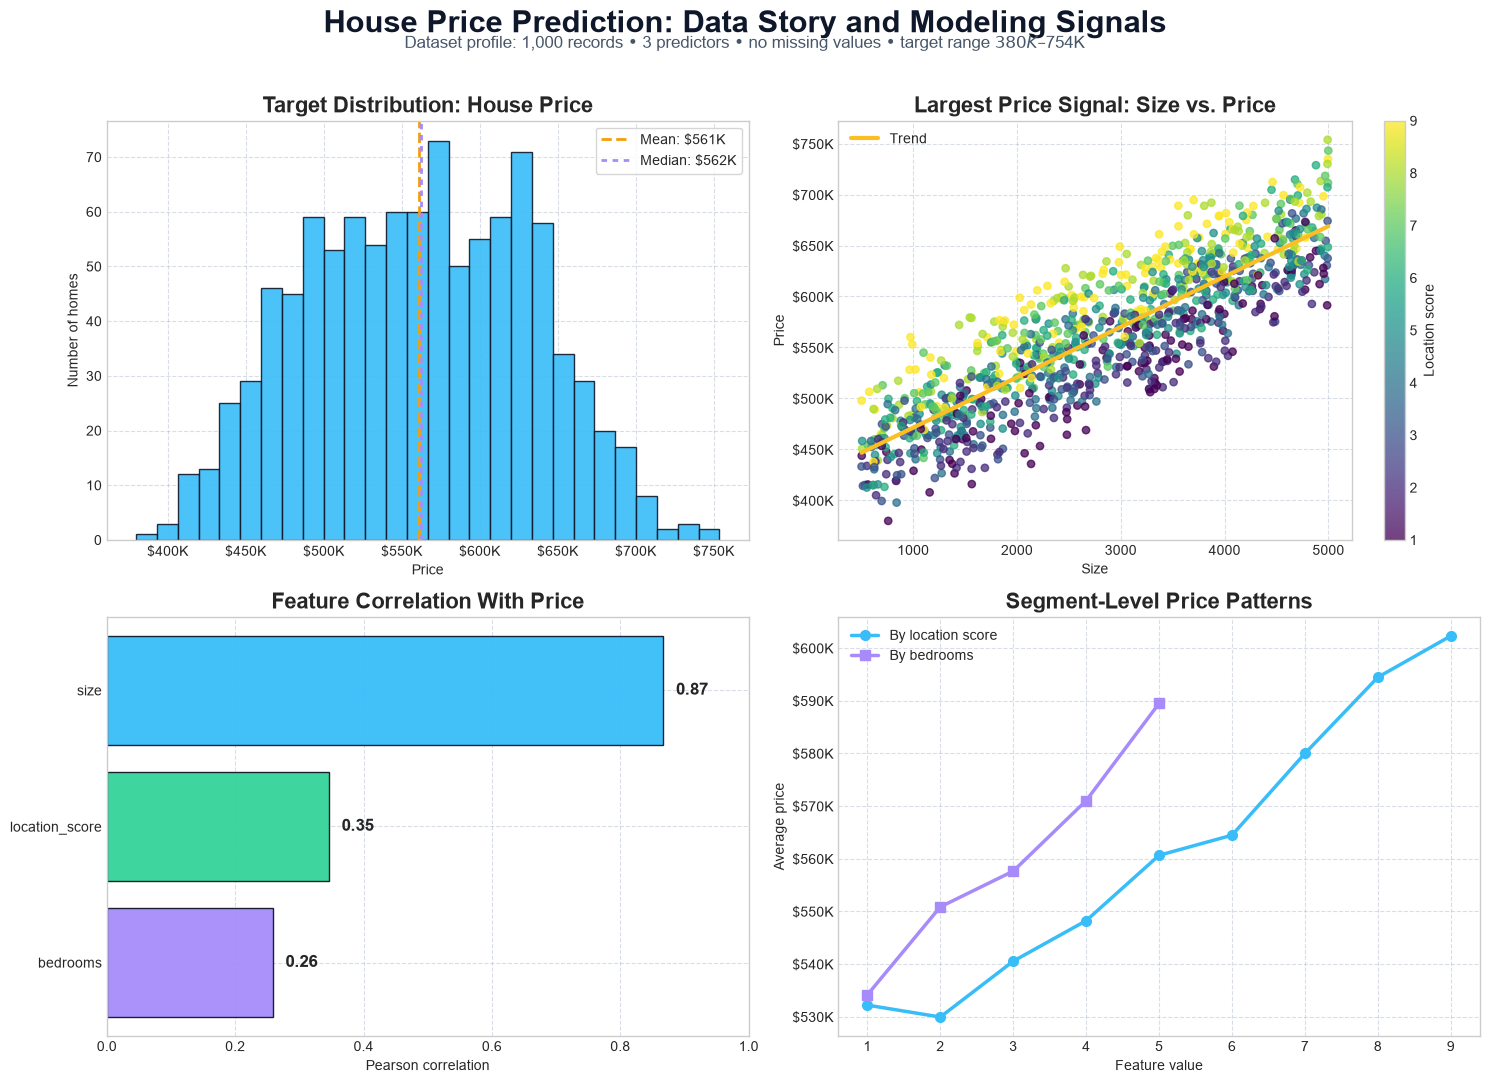

In [5]:
# Portfolio-style EDA dashboard
#Chuẩn bị dữ liệu cho các biểu đồ và phân tích
price_corr = ( #Tính tương quan Pearson giữa các biến với giá nhà   
    data.corr(numeric_only=True)["price"]
    .drop("price")
    .sort_values(ascending=False)
)
# Hệ số tương quan Pearson là gì?
# Hệ số tương quan Pearson, ký hiệu \(r\), đo lường mức độ và chiều hướng của mối quan hệ tuyến tính giữa hai biến.

# Giá trị nằm trong khoảng: -1 <= r <= 1
# r gần 1: tương quan tuyến tính dương mạnh.
# r gần 0: ít có quan hệ tuyến tính.
# r gần -1: tương quan tuyến tính âm mạnh.
# Trong dữ liệu của nhóm:
# - size có tương quan 0.87 với price: nhà có diện tích lớn hơn thường có giá cao hơn, và đây là mối quan hệ tuyến tính tương đối mạnh.
# - location_score có tương quan 0.35: điểm vị trí cao hơn có xu hướng đi cùng giá nhà cao hơn, nhưng quan hệ yếu hơn diện tích.
# - bedrooms có tương quan 0.26: số phòng ngủ có tương quan dương với giá nhà, nhưng mức độ tương quan tuyến tính thấp hơn hai biến còn lại.
# Điểm quan trọng: Tương quan không chứng minh quan hệ nhân quả. Chẳng hạn, ta không thể chỉ dựa vào hệ số 0.35 để kết luận rằng việc tăng điểm vị trí trực tiếp làm giá nhà tăng.
location_profile = data.groupby("location_score")["price"].mean().sort_index() #Phần này chia dữ liệu thành các nhóm theo location_score, sau đó tính giá nhà trung bình trong từng nhóm.
bedroom_profile = data.groupby("bedrooms")["price"].mean().sort_index() #Cách làm tương tự, nhưng lần này các căn nhà được chia thành nhóm theo số phòng ngủ. 
#Kết quả được dùng để vẽ đường màu tím trong biểu đồ Segment-Level Price Patterns.

fig, axes = plt.subplots(2, 2, figsize=(15, 11)) #Tạo khung dashboard gồm 4 biểu đồ
fig.suptitle(
    "House Price Prediction: Data Story and Modeling Signals",
    fontsize=22,
    fontweight="bold",
    color=COLORS["dark"],
    y=0.98
)
fig.text(
    0.5,
    0.945,
    f"Dataset profile: {len(data):,} records • 3 predictors • no missing values • target range ${data['price'].min()/1000:,.0f}K–${data['price'].max()/1000:,.0f}K",
    ha="center",
    fontsize=12,
    color="#475569"
)

# Panel 1: price distribution - Biểu đồ 1 – Phân phối giá nhà
#Đây là Histogram – biểu đồ tần suất, dùng để xem phân phối của biến mục tiêu price.
ax = axes[0, 0]
ax.hist(data["price"], bins=28, color=COLORS["blue"], edgecolor=COLORS["dark"], alpha=0.9) #bins=28: chia khoảng giá thành 28 khoảng nhỏ.
#Chiều cao mỗi cột biểu thị số căn nhà nằm trong khoảng giá tương ứng.
ax.axvline(data["price"].mean(), color=COLORS["orange"], linestyle="--", linewidth=2, label=f"Mean: ${data['price'].mean()/1000:,.0f}K")
ax.axvline(data["price"].median(), color=COLORS["purple"], linestyle=(0, (2, 2)), linewidth=2, label=f"Median: ${data['price'].median()/1000:,.0f}K")
#Hai dòng ax.axvline(...) vẽ hai đường thẳng đứng: Đường cam nét đứt: giá trung bình (Mean), khoảng 561K. Đường tím nét đứt: giá trung vị (Median), khoảng 562K nên giá trung bình và giá trung vị gần nhau nên điều này gợi ý rằng phân phối giá không bị lệch mạnh theo một phía. 
#Tuy nhiên, chỉ nhìn Mean và Median thì chưa đủ để khẳng định phân phối hoàn toàn đối xứng.
#Phân tích phân phối giúp nhóm:
# - Hiểu phạm vi giá nhà trong dataset.
# - Xác định vùng giá có nhiều quan sát.
# - Nhận biết khả năng tồn tại giá trị cực đoan.
# - Có bối cảnh để diễn giải sai số dự đoán sau này.
ax.set_title("Target Distribution: House Price", fontsize=16, fontweight="bold")
ax.set_xlabel("Price")
ax.set_ylabel("Number of homes")
ax.xaxis.set_major_formatter(FuncFormatter(currency_k))
ax.legend(frameon=True)

# Panel 2: size vs. price, colored by location score  - Biểu đồ 2 – Mối quan hệ giữa diện tích và giá nhà
#Đây là biểu đồ Largest Price Signal: Size vs. Price. Đoạn này tạo biểu đồ Scatter Plot.
# Mỗi chấm biểu diễn một căn nhà:
# - Trục X: diện tích (size).
# - Trục Y: giá nhà (price).
# - Màu sắc: điểm vị trí (location_score).
ax = axes[0, 1]
sc = ax.scatter(
    data["size"],
    data["price"],
    c=data["location_score"], #Màu sắc được gán theo điểm vị trí, Thang màu viridis chuyển từ màu tím đậm sang xanh lá và vàng. 
    #Trong hình, màu vàng thường đại diện cho điểm vị trí cao hơn, màu tím đại diện cho điểm thấp hơn.
    cmap="viridis",
    alpha=0.75,
    s=28
)
trend = np.polyfit(data["size"], data["price"], 1) #np.polyfit tìm một đường thẳng phù hợp nhất với dữ liệu theo phương pháp bình phương tối thiểu.
trend_x = np.linspace(data["size"].min(), data["size"].max(), 200) #np.linspace tạo một mảng gồm 200 giá trị đều nhau từ diện tích nhỏ nhất đến diện tích lớn nhất trong dữ liệu. Đây là các giá trị X để vẽ đường xu hướng.
trend_y = trend[0] * trend_x + trend[1]
ax.plot(trend_x, trend_y, color=COLORS["gold"], linewidth=3, label="Trend")
ax.set_title("Largest Price Signal: Size vs. Price", fontsize=16, fontweight="bold")
ax.set_xlabel("Size")
ax.set_ylabel("Price")
ax.yaxis.set_major_formatter(FuncFormatter(currency_k))
ax.legend(loc="upper left")
fig.colorbar(sc, ax=ax, label="Location score")
#Đọc kết quả thì Trong ảnh, các điểm dữ liệu có xu hướng đi lên khi diện tích tăng. Điều này cho thấy: Những căn nhà có diện tích lớn hơn thường có giá cao hơn.
#Đường xu hướng giúp nhìn rõ xu hướng tổng thể dù dữ liệu có độ phân tán. Ngoài ra, các chấm có màu sắc khác nhau ở cùng mức diện tích cũng gợi ý rằng điểm vị trí có thể liên quan đến sự khác biệt về giá.

# Panel 3: correlations with price - Biểu đồ 3 – Tương quan giữa các đặc trưng và giá nhà
# Đây là biểu đồ thanh ngang (barh).
# - Trục Y: tên các feature.
# - Trục X: hệ số tương quan Pearson với price.
# - Chiều dài thanh: độ lớn của hệ số tương quan.
ax = axes[1, 0]
bar_colors = [COLORS["blue"], COLORS["teal"], COLORS["purple"]]
ax.barh(price_corr.index, price_corr.values, color=bar_colors, edgecolor=COLORS["dark"], alpha=0.95)
ax.invert_yaxis()
for i, value in enumerate(price_corr.values):
    ax.text(value + 0.02, i, f"{value:.2f}", va="center", fontsize=12, fontweight="bold")
ax.set_xlim(0, 1.0)
ax.set_title("Feature Correlation With Price", fontsize=16, fontweight="bold")
ax.set_xlabel("Pearson correlation")
# Đọc kết quả
# Từ biểu đồ:
# - size: 0.87.
# - location_score: 0.35.
# - bedrooms: 0.26.
# Trong phạm vi dataset này, size có mối quan hệ tuyến tính mạnh nhất với price.

# Biểu đồ này bổ sung cho Scatter Plot ở phần trước. Scatter Plot cho thấy mối quan hệ bằng hình ảnh, còn biểu đồ tương quan giúp định lượng và so sánh mối quan hệ tuyến tính giữa các biến.

# Panel 4: grouped price patterns - Biểu đồ 4 – Giá trung bình theo từng nhóm
ax = axes[1, 1]
ax.plot(location_profile.index, location_profile.values, marker="o", linewidth=2.5, markersize=7, color=COLORS["blue"], label="By location score")
ax.plot(bedroom_profile.index, bedroom_profile.values, marker="s", linewidth=2.5, markersize=7, color=COLORS["purple"], label="By bedrooms")
ax.set_title("Segment-Level Price Patterns", fontsize=16, fontweight="bold")
ax.set_xlabel("Feature value")
ax.set_ylabel("Average price")
ax.yaxis.set_major_formatter(FuncFormatter(currency_k))
ax.legend(loc="upper left")

for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.35, color="#94A3B8")

plt.tight_layout(rect=[0, 0, 1, 0.955])
save_figure(fig, "house_price_data_story.png")
plt.show()
# Biểu đồ này có hai đường:
# - Đường xanh: giá trung bình theo location_score.
# - Đường tím: giá trung bình theo bedrooms.
# Ví dụ, nếu đường xanh tại điểm 8 cao hơn điểm 4, điều đó có nghĩa là nhóm nhà có location_score = 8 có giá trung bình cao hơn nhóm có location_score = 4.

# Tương tự, đường tím cho biết giá trung bình thay đổi như thế nào theo số phòng ngủ.
# Đọc kết quả trong ảnh
# Đường xanh nhìn chung có xu hướng tăng khi điểm vị trí tăng. Điều này phù hợp với hệ số tương quan dương 0.35 ở biểu đồ trước.

# Đường tím cũng tăng khi số phòng ngủ tăng trong các nhóm được hiển thị. Tuy nhiên, cần lưu ý rằng số phòng ngủ và diện tích có thể liên quan với nhau: nhà nhiều phòng ngủ thường cũng có diện tích lớn hơn. Vì vậy, biểu đồ này chưa tách riêng ảnh hưởng của số phòng ngủ khỏi diện tích.
# Một điểm cần lưu ý về biểu đồ này
# Hai đường dùng chung trục X nhưng biểu diễn hai biến có ý nghĩa khác nhau:
# - location_score: điểm vị trí.
# - bedrooms: số phòng ngủ.
# Do đó, không nên so sánh trực tiếp tọa độ X giữa hai đường như thể chúng cùng một loại biến. Biểu đồ chủ yếu giúp quan sát xu hướng của từng nhóm.

In [6]:
# Supporting summary tables for the EDA dashboard

correlation_table = price_corr.to_frame("correlation_with_price")
profile_table = pd.DataFrame({
    "avg_price_by_location_score": location_profile,
    "avg_price_by_bedrooms": bedroom_profile.reindex(location_profile.index)
})

print("Feature correlations with price")
display(correlation_table)

print("Segment-level average price profiles")
display(profile_table)

Feature correlations with price


,correlation_with_price
size,0.867
location_score,0.346
bedrooms,0.258


Segment-level average price profiles


,avg_price_by_location_score,avg_price_by_bedrooms
location_score,,
1,"532,164.300","534,118.995"
2,"529,902.392","550,816.268"
3,"540,508.320","557,604.942"
4,"548,199.276","570,996.121"
5,"560,615.319","589,460.165"
6,"564,431.380",NaN
7,"579,958.579",NaN
8,"594,420.944",NaN
9,"602,271.702",NaN


### EDA Findings

The target variable is centered around the mid-$500K range, with a mean price of approximately **$560,966** and a median price of approximately **$562,265**.

The correlation results show a clear feature hierarchy:

- `size` has the strongest relationship with price, with a correlation of **0.867**
- `location_score` has a moderate positive relationship, with a correlation of **0.346**
- `bedrooms` has a weaker but still positive relationship, with a correlation of **0.258**

The scatter plots support the same interpretation. Larger homes tend to sell for more, while location quality and bedrooms add secondary signal. This suggests that a strong baseline model should perform well, so the neural network needs to be judged against simpler regression models rather than evaluated in isolation.
#price là biến mục tiêu, tức là giá nhà mà mô hình cần dự đoán.

## 4. Train/Test Split and Scaling

The dataset is split into training and test sets using an 80/20 split. The training set is used to fit the preprocessing scalers and train the models, while the test set is held out for final evaluation.

Both the input features and the target are standardized for neural-network training. Scaling the target helps the neural network optimize more smoothly, but it also creates an important reporting requirement: predictions must be inverse-transformed back into dollars before MAE, RMSE, and residuals are interpreted.


In [7]:
feature_names = ["size", "location_score", "bedrooms"]
target_name = "price"

X = data[feature_names]
y = data[target_name]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.to_numpy().reshape(-1, 1)).ravel()

print(f"Training rows: {X_train.shape[0]}")
print(f"Test rows: {X_test.shape[0]}")

Training rows: 800
Test rows: 200


## 5. Neural Network Model

The neural network uses a compact feedforward architecture with two hidden layers: 64 ReLU units followed by 32 ReLU units, then a single regression output.

This architecture is intentionally modest because the dataset has only three predictors. A much larger network would be difficult to justify and could overfit without adding meaningful predictive value.

The model has **2,369 trainable parameters**, which is small enough for this structured regression problem while still allowing the network to learn nonlinear relationships among size, location score, and bedroom count.


In [ ]:
nn_model = Sequential([ #Sequential là một mô hình tuần tự trong Keras, nơi các lớp được xếp chồng lên nhau theo thứ tự. Mỗi lớp nhận đầu ra từ lớp trước đó làm đầu vào của nó.
    Input(shape=(X_train_scaled.shape[1],)), #Input(shape=(số lượng đặc trưng,)) trả về 3 vì có 3 đầu vào
    Dense(64, activation="relu"), #Tạo hidden layer đầu tiên với 64 neurons 
    Dense(32, activation="relu"),
    Dense(1)
])

nn_model.compile( #Lệnh compile() được sử dụng để cấu hình mô hình trước khi huấn luyện. Nó xác định cách mô hình sẽ học từ dữ liệu, bao gồm thuật toán tối ưu hóa, hàm mất mát và các chỉ số đánh giá hiệu suất.
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), #Adam là optimizer phổ biến trong học sâu, kết hợp các ưu điểm của hai phương pháp: AdaGrad và RMSProp. 
    #Nó điều chỉnh tốc độ học cho từng tham số dựa trên các gradient trước đó, giúp mô hình hội tụ nhanh hơn và ổn định hơn. learning rate là tốc độ, quyết định mức độ điều chỉnh trọng số trong mỗi bước cập nhật. 
    #Giá trị 0.01 là một tốc độ học tương đối cao, có thể giúp mô hình học nhanh hơn nhưng cũng có nguy cơ bỏ qua cực tiểu toàn cục nếu quá cao.
    loss="mean_squared_error",
    metrics=["mae"]
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,369 (9.25 KB)

 Trainable params: 2,369 (9.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = EarlyStopping( #EarlyStopping – Dừng huấn luyện khi mô hình không còn cải thiện. Đây là một cơ chế giúp hạn chế overfitting và tránh huấn luyện không cần thiết.
    monitor="val_loss", #Mô hình theo dõi loss trên validation set.
    patience=10, #Có nghĩa là nếu val_loss không cải thiện trong 10 epochs liên tiếp, EarlyStopping sẽ dừng quá trình training.
    restore_best_weights=True #Nó yêu cầu mô hình khôi phục lại weights tại epoch có validation loss tốt nhất.
)
# Ví dụ:
# - Epoch 5 có val_loss thấp nhất.
# - Mô hình tiếp tục training đến epoch 15.
# - EarlyStopping quyết định dừng.
# - Weights ở epoch 5 được khôi phục.
# Như vậy, mô hình không nhất thiết sử dụng weights của epoch cuối cùng.
#Validation set là tập dữ liệu được giữ lại từ training set để đánh giá khả năng tổng quát hóa trong quá trình huấn luyện.
history = nn_model.fit(
    X_train_scaled, #Features đã chuẩn hóa
    y_train_scaled, #Target đã chuẩn hóa
    validation_split=0.20, #Nghĩa là 20% dữ liệu training được sử dụng làm validation set.
    epochs=100, #Số epoch tối đa mà mô hình có thể chạy. Không có nghĩa là mô hình chắc chắn chạy đủ 100 epochs.
    #Nếu EarlyStopping phát hiện validation loss không cải thiện trong 10 epochs liên tiếp, quá trình training có thể dừng sớm hơn.
    batch_size=32, #Mỗi batch gồm 32 mẫu
    callbacks=[early_stop], #Sử dụng EarlyStopping
    verbose=1 #Hiển thị tiến trình training
)
#Một epoch là một lượt mô hình đi qua toàn bộ dữ liệu training được dùng để cập nhật weights. Nếu có 640 mẫu thực sự được dùng để training và batch_size=32, thì mỗi epoch có: 640/32 = 20 batch. 
#Vì vậy, nếu mô hình dừng ở epoch 15, thì tổng cộng có 15*20 = 300 batch được dùng để cập nhật weights.
#Batch size là gì? nếu viết batch_size = 32 thì có nghĩa là mô hình xử lý 32 mẫu trong một batch trước khi cập nhật weights.

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2001 - mae: 0.3228 - val_loss: 0.0700 - val_mae: 0.2110
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0543 - mae: 0.1911 - val_loss: 0.0514 - val_mae: 0.1906
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0427 - mae: 0.1738 - val_loss: 0.0430 - val_mae: 0.1768
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0410 - mae: 0.1700 - val_loss: 0.0436 - val_mae: 0.1777
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0407 - mae: 0.1692 - val_loss: 0.0436 - val_mae: 0.1780
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0402 - mae: 0.1683 - val_loss: 0.0430 - val_mae: 0.1774
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0403 - mae: 0.1682 - val_loss: 0.0441 - val_mae: 0.1788
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0405 - mae: 0.1687 - val_loss: 0.0449 - val_mae: 0.1800
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.040

### Training Findings

The neural network converged quickly. Validation loss improved sharply in the first few epochs and then stabilized, with early stopping ending training after **13 epochs**.

This is a good sign for this dataset. The model learned the main signal quickly, and the early-stopping callback helped prevent unnecessary training once validation performance stopped improving. Because the dataset has only three predictors, fast convergence is expected.

<!-- Mạng nơ-ron hội tụ nhanh. -->
<!-- Trong quá trình training, mô hình liên tục điều chỉnh các trọng số (weights) để giảm sai số dự đoán.
- Ban đầu, mô hình dự đoán chưa tốt nên loss thường khá cao.
- Sau mỗi epoch, mô hình cập nhật weights.
- Khi loss không còn giảm đáng kể nữa, ta nói mô hình đang tiến gần đến trạng thái hội tụ.
Validation loss giảm mạnh trong vài epoch đầu, sau đó ổn định.
Validation loss là sai số của mô hình trên tập validation — dữ liệu được dùng để theo dõi khả năng dự đoán trên những mẫu không được sử dụng trực tiếp để cập nhật weights. Cơ chế Early Stopping đã kết thúc quá trình huấn luyện sau 13 epoch. -->
<!-- Với số lượng biến đầu vào tương đối nhỏ và cấu trúc dữ liệu không quá phức tạp, việc mô hình hội tụ nhanh là điều có thể xảy ra.Tuy nhiên, cần hiểu chính xác rằng hội tụ nhanh không tự động chứng minh mô hình dự đoán tốt. Muốn đánh giá mô hình có dự đoán giá nhà chính xác hay không, bạn vẫn cần xem các chỉ số trên tập test, chẳng hạn MAE. -->

## 6. Neural Network Evaluation in Real Dollar Terms

The model predicts standardized prices, so the predictions are converted back into dollars before evaluation.

This is one of the most important aspects of the project. Reporting MAE or RMSE on the scaled target would make the result hard to interpret. Dollar-based metrics make the model understandable to both technical and non-technical reviewers.


In [10]:
# Predict on the test set.
# The model predicts scaled prices, so predictions must be converted back to dollars before reporting portfolio metrics.

y_pred_scaled = nn_model.predict(X_test_scaled).ravel()

y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
y_test_actual = y_test.to_numpy()

nn_metrics = {
    "MAE": mean_absolute_error(y_test_actual, y_pred),
    "RMSE": mean_squared_error(y_test_actual, y_pred) ** 0.5,
    "R2": r2_score(y_test_actual, y_pred)
}

pd.DataFrame([nn_metrics], index=["Neural Network"])
#Neural Network Evaluation in Real Dollar Terms đang làm 3 việc chính:
# 1. Dùng Neural Network dự đoán giá nhà trên tập test. Kết quả ban đầu là giá đã chuẩn hóa.
# 2. Chuyển giá dự đoán về đơn vị USD, để có thể so sánh trực tiếp với giá nhà thực tế.
# 3. Tính MAE, RMSE và R² để đánh giá mô hình dự đoán giá nhà tốt đến đâu.
# Trong đó:
# MAE: Trung bình mô hình dự đoán lệch bao nhiêu USD.
# RMSE: Đánh giá sai số, chú ý hơn đến những dự đoán sai rất lớn.
# R²: Đánh giá mức độ mô hình giải thích sự biến thiên của giá nhà.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


,MAE,RMSE,R2
Neural Network,"11,565.780","13,940.084",0.961



### Benchmark Findings

The benchmark comparison evaluates three models: Neural Network, Linear Regression, and Random Forest.

The results are used to investigate whether the neural network provides a meaningful improvement over a simple linear baseline and a non-linear tree-based model.

MAE, RMSE, and R² are reported on the original house-price scale.

The model with the lowest MAE produces the smallest average absolute prediction error. However, the best model should not be selected based on MAE alone. RMSE and R² provide additional information about prediction errors and overall model fit.

The comparison also helps explain whether the relationships between property features and house prices are mostly linear or whether non-linear modeling provides additional predictive value.

The final conclusions should be based on the actual results obtained after running the notebook.

Phần này gồm hai nội dung chính:
1. Benchmark Findings: giải thích mục đích so sánh Neural Network với Linear Regression và Random Forest.
2. Learning Curves: vẽ biểu đồ thể hiện quá trình Neural Network học qua từng epoch, giúp quan sát training loss, validation loss và MAE.

Saved figure to D:\Intro_to_DL_BTL\house-price-prediction-main\images\house_price_nn_training_curves.png


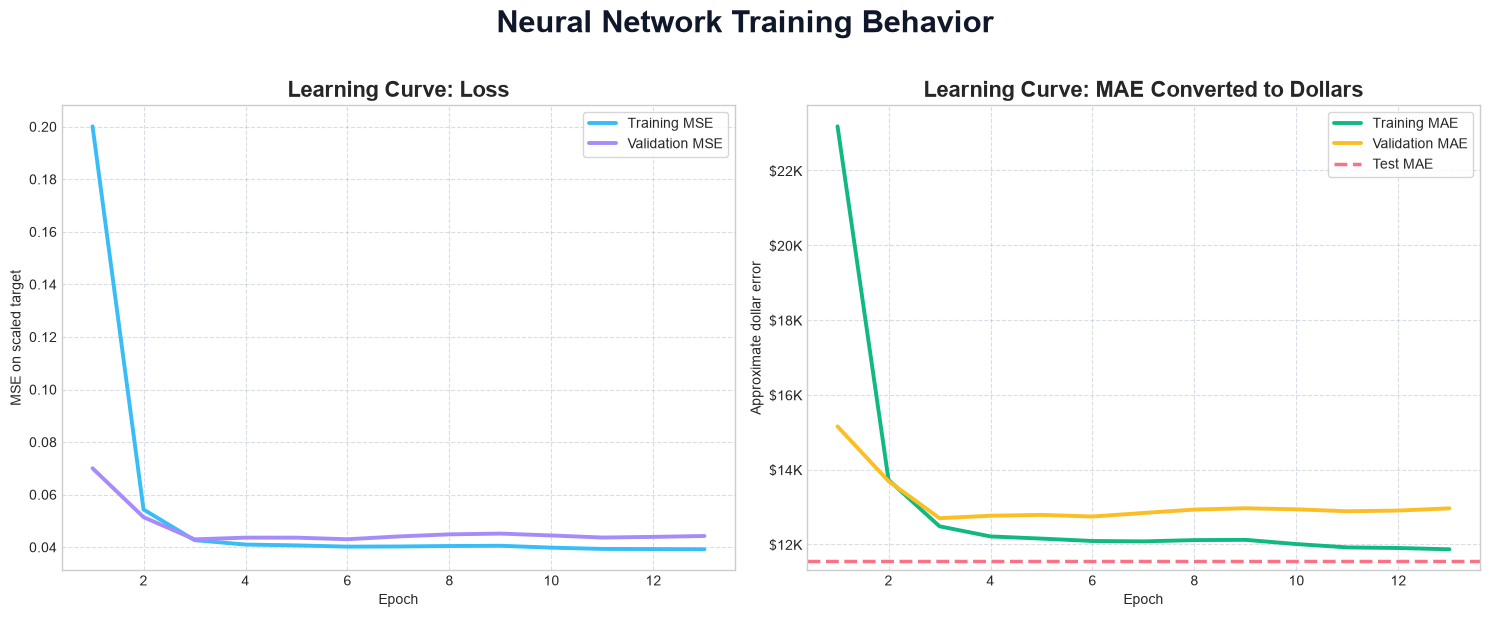

In [11]:
# Learning curves with clearer color coding and image export

history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(
    "Neural Network Training Behavior",
    fontsize=22,
    fontweight="bold",
    color=COLORS["dark"],
    y=1.02
)
#Biểu đồ trái cho thấy MSE thay đổi qua từng epoch.
axes[0].plot(history_df.index + 1, history_df["loss"], linewidth=2.8, color=COLORS["blue"], label="Training MSE")
axes[0].plot(history_df.index + 1, history_df["val_loss"], linewidth=2.8, color=COLORS["purple"], label="Validation MSE")
axes[0].set_title("Learning Curve: Loss", fontsize=16, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE on scaled target")
axes[0].legend(frameon=True)
#Biểu đồ phải cho thấy MAE theo đơn vị USD qua từng epoch.
axes[1].plot(history_df.index + 1, history_df["mae"] * scaler_y.scale_[0], linewidth=2.8, color=COLORS["green"], label="Training MAE")
axes[1].plot(history_df.index + 1, history_df["val_mae"] * scaler_y.scale_[0], linewidth=2.8, color=COLORS["gold"], label="Validation MAE")
axes[1].axhline(nn_metrics["MAE"], linestyle="--", linewidth=2.5, color=COLORS["pink"], label="Test MAE")
axes[1].set_title("Learning Curve: MAE Converted to Dollars", fontsize=16, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Approximate dollar error")
axes[1].yaxis.set_major_formatter(FuncFormatter(currency_k))
axes[1].legend(frameon=True)

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.35, color="#94A3B8")

plt.tight_layout()
save_figure(fig, "house_price_nn_training_curves.png")
plt.show()

Saved figure to D:\Intro_to_DL_BTL\house-price-prediction-main\images\house_price_prediction_diagnostics.png


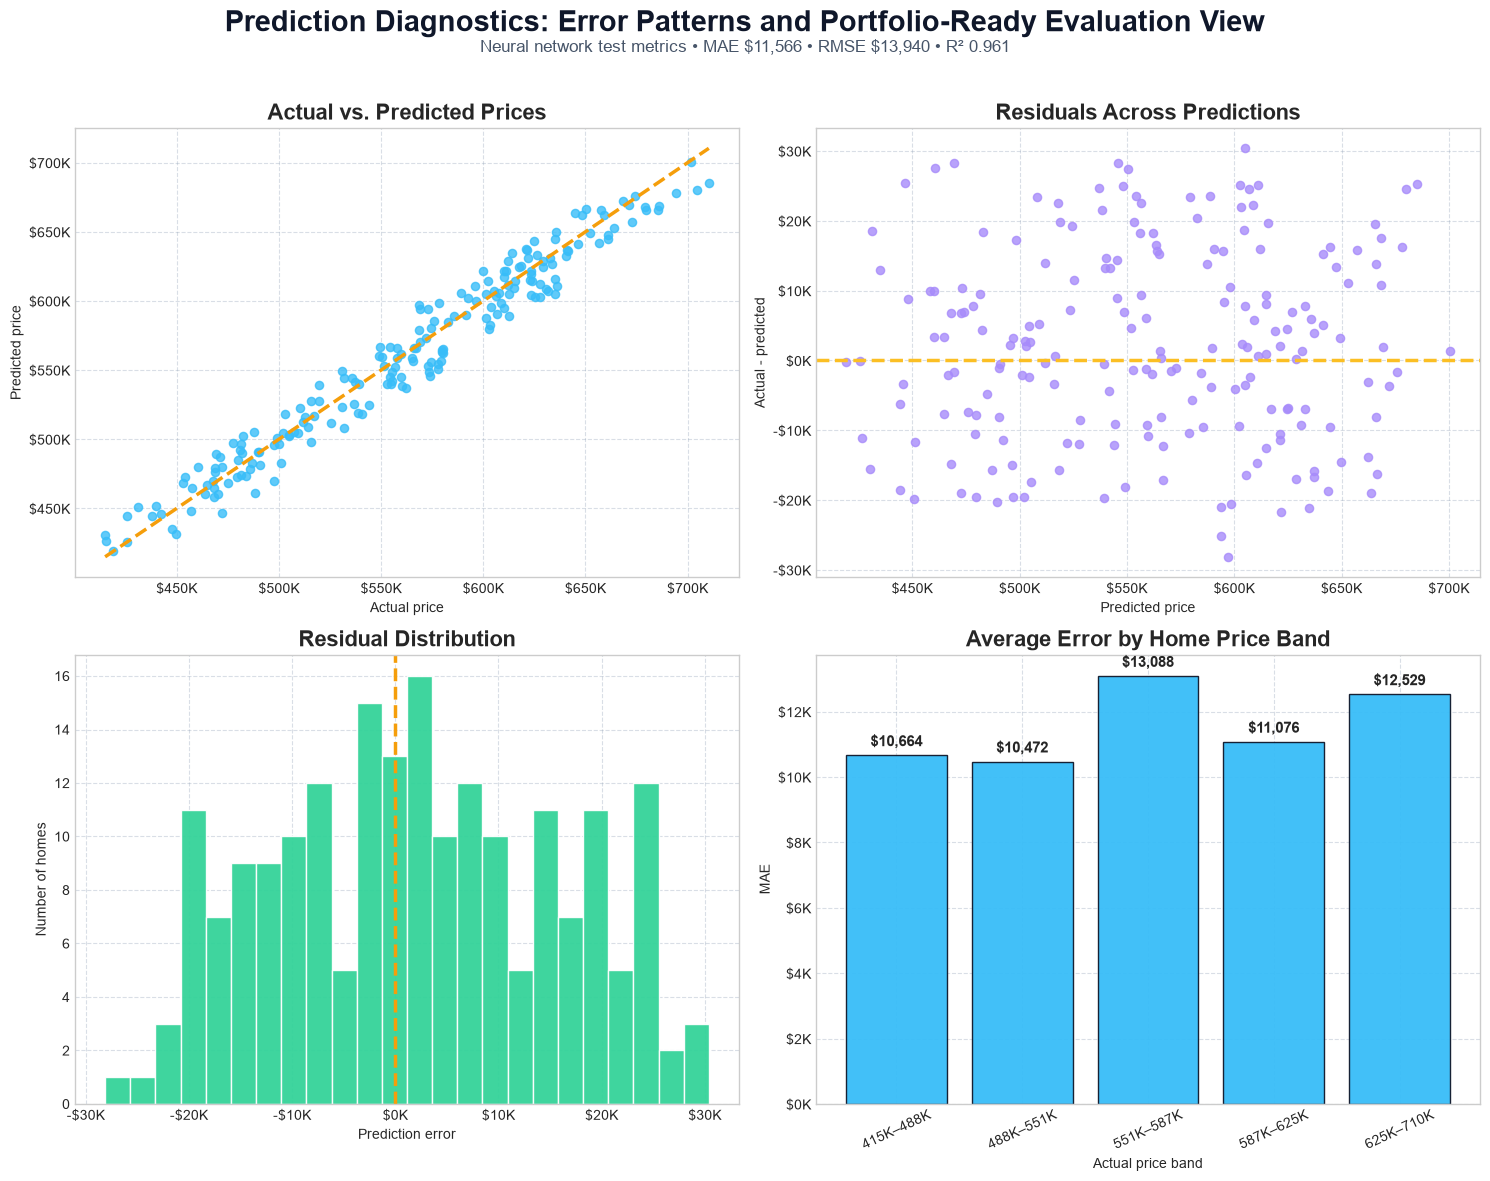

Mean residual: $2,133
Median absolute error: $10,538


In [12]:
# Prediction diagnostics dashboard
# Còn ở phần này, nhóm đã có mô hình và kết quả dự đoán trên tập test và giờ muốn kiểm tra sâu hơn:
# - Mô hình dự đoán giá nhà có sát với giá thực tế không?
# - Mô hình thường dự đoán cao hơn hay thấp hơn giá thực tế?
# - Sai số phân bố như thế nào?
# - Mô hình dự đoán tốt với nhà giá thấp, trung bình hay nhà giá cao?
# - Có những mẫu nhà nào mà mô hình dự đoán sai nhiều?
y_test_actual_arr = np.asarray(y_test_actual).ravel()
y_pred_arr = np.asarray(y_pred).ravel()

residuals = y_test_actual_arr - y_pred_arr
abs_errors = np.abs(residuals)

price_bands = pd.qcut(
    pd.Series(y_test_actual_arr),
    q=5,
    duplicates="drop"
)

error_by_band = (
    pd.DataFrame({
        "price_band": price_bands.astype(str),
        "abs_error": abs_errors
    })
    .groupby("price_band", observed=False)["abs_error"]
    .mean()
)

ordered_labels = [str(interval) for interval in price_bands.cat.categories]
error_by_band = error_by_band.reindex(ordered_labels)

pretty_labels = [
    f"{interval.left/1000:,.0f}K–{interval.right/1000:,.0f}K"
    for interval in price_bands.cat.categories
]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

fig.suptitle(
    "Prediction Diagnostics: Error Patterns and Portfolio-Ready Evaluation View",
    fontsize=21,
    fontweight="bold",
    color=COLORS["dark"],
    y=0.98
)

fig.text(
    0.5,
    0.945,
    (
        f"Neural network test metrics • "
        f"MAE {currency_full(nn_metrics['MAE'])} • "
        f"RMSE {currency_full(nn_metrics['RMSE'])} • "
        f"R² {nn_metrics['R2']:.3f}"
    ),
    ha="center",
    fontsize=12,
    color="#475569"
)

# Actual vs predicted
ax = axes[0, 0]

ax.scatter(
    y_test_actual_arr,
    y_pred_arr,
    color=COLORS["blue"],
    alpha=0.8,
    s=35
)

min_price = min(y_test_actual_arr.min(), y_pred_arr.min())
max_price = max(y_test_actual_arr.max(), y_pred_arr.max())

ax.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=2.5,
    color=COLORS["orange"]
)

ax.set_title("Actual vs. Predicted Prices", fontsize=16, fontweight="bold")
ax.set_xlabel("Actual price")
ax.set_ylabel("Predicted price")
ax.xaxis.set_major_formatter(FuncFormatter(currency_k))
ax.yaxis.set_major_formatter(FuncFormatter(currency_k))

# Residuals vs predictions
ax = axes[0, 1]

ax.scatter(
    y_pred_arr,
    residuals,
    color=COLORS["purple"],
    alpha=0.8,
    s=35
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=2.5,
    color=COLORS["gold"]
)

ax.set_title("Residuals Across Predictions", fontsize=16, fontweight="bold")
ax.set_xlabel("Predicted price")
ax.set_ylabel("Actual - predicted")
ax.xaxis.set_major_formatter(FuncFormatter(currency_k))
ax.yaxis.set_major_formatter(FuncFormatter(currency_k))

# Residual histogram
ax = axes[1, 0]

ax.hist(
    residuals,
    bins=24,
    color=COLORS["teal"],
    edgecolor="white",
    alpha=0.95
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=2.5,
    color=COLORS["orange"]
)

ax.set_title("Residual Distribution", fontsize=16, fontweight="bold")
ax.set_xlabel("Prediction error")
ax.set_ylabel("Number of homes")
ax.xaxis.set_major_formatter(FuncFormatter(currency_k))

# Error by price band
ax = axes[1, 1]

bar_positions = np.arange(len(pretty_labels))

ax.bar(
    bar_positions,
    error_by_band.values,
    color=COLORS["blue"],
    edgecolor=COLORS["dark"],
    alpha=0.95
)

for i, value in enumerate(error_by_band.values):
    ax.text(
        i,
        value + 180,
        currency_full(value),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("Average Error by Home Price Band", fontsize=16, fontweight="bold")
ax.set_ylabel("MAE")
ax.set_xlabel("Actual price band")
ax.set_xticks(bar_positions)
ax.set_xticklabels(pretty_labels, rotation=25)
ax.yaxis.set_major_formatter(FuncFormatter(currency_k))

for ax in axes.flat:
    ax.grid(True, linestyle="--", alpha=0.35, color="#94A3B8")

plt.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(fig, "house_price_prediction_diagnostics.png")
plt.show()

print(f"Mean residual: {currency_full_plain(residuals.mean())}")
print(f"Median absolute error: {currency_full_plain(np.median(abs_errors))}")

### Prediction Diagnostic Findings

The actual-vs-predicted plot shows that predictions follow the diagonal closely, which aligns with the high R² score.

The residual summary adds useful nuance:

- **Mean residual:** $2,132.91
- **Median absolute error:** $10,538.38

The positive mean residual means the model slightly underpredicts on average because residuals are calculated as actual minus predicted. The median absolute error being close to the MAE suggests that the error distribution is not being dominated by only a few extreme misses.


## 7. Baseline Model Comparison

This section compares three regression models:

- Linear Regression
- Neural Network
- Random Forest

Linear Regression is used as a simple baseline to evaluate whether a neural network provides meaningful improvement.

Random Forest is included as a non-linear machine-learning benchmark. It helps determine whether a tree-based ensemble model can capture relationships that a linear model may not represent.

All three models are evaluated on the same test set using MAE, RMSE, and R².

The goal is to identify which model performs best on this dataset and understand whether the additional complexity of a neural network is justified.


In [13]:

# Compare Neural Network with two traditional ML models

baseline_models = { #Khởi tạo hai mô hình baseline
    "Linear Regression": LinearRegression(), #Tạo mô hình Linear

    "Random Forest": RandomForestRegressor( #Tạo mô hình Random Forest Regressor với các tham số:
        n_estimators=300, #Random Forest xây dựng 300 cây quyết định
        min_samples_leaf=3, #Mỗi nút lá phải chứa ít nhất 3 mẫu huấn luyện
        random_state=SEED #Cố định random_state để đảm bảo kết quả có thể tái lập
    )
}

# Store Neural Network results first
comparison_rows = [{ #Lưu kết quả của Neural Network vào danh sách comparison_rows để so sánh với các mô hình baseline.
    "model": "Neural Network",
    "MAE": nn_metrics["MAE"],
    "RMSE": nn_metrics["RMSE"],
    "R2": nn_metrics["R2"]
}]

# Train and evaluate the baseline models
for model_name, baseline_model in baseline_models.items(): #Lấy từng mô hình baseline trong dictionary baseline_models để huấn luyện và đánh giá.

    baseline_model.fit(X_train, y_train) #huấn luyện 2 mô hình baseline trên tập huấn luyện (X_train, y_train).

    baseline_pred = baseline_model.predict(X_test) #Dự đoán giá nhà trên tập test (X_test) bằng mô hình baseline vừa huấn luyện.

    comparison_rows.append({ #Sau khi dự đoán, lưu kết quả đánh giá của mô hình baseline vào danh sách comparison_rows để so sánh với Neural Network.
        "model": model_name,
        "MAE": mean_absolute_error(y_test, baseline_pred),
        "RMSE": mean_squared_error(y_test, baseline_pred) ** 0.5,
        "R2": r2_score(y_test, baseline_pred)
    })

# Create the comparison table
comparison = pd.DataFrame(comparison_rows).sort_values("MAE")#Tạo bảng DataFrame từ danh sách comparison_rows và sắp xếp theo MAE để dễ dàng so sánh hiệu suất của các mô hình.

display(comparison)


,model,MAE,RMSE,R2
0,Neural Network,"11,565.780","13,940.084",0.961
1,Linear Regression,"11,798.367","13,877.589",0.961
2,Random Forest,"13,618.119","16,338.528",0.946


Saved figure to D:\Intro_to_DL_BTL\house-price-prediction-main\images\house_price_model_benchmark.png


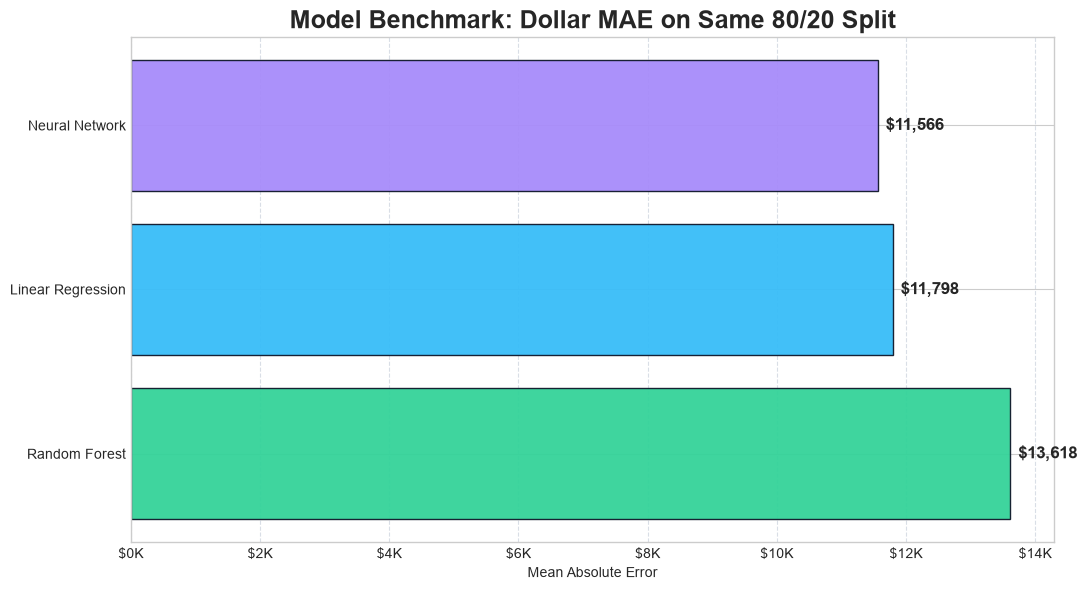

In [14]:

# Visualize model comparison - Tạo biểu đồ so sánh hiệu suất của các mô hình dựa trên MAE.

plot_df = comparison.sort_values( #Tạo một DataFrame mới plot_df từ comparison, sắp xếp theo MAE để chuẩn bị cho việc vẽ biểu đồ so sánh hiệu suất của các mô hình.
    "MAE",
    ascending=True
).reset_index(drop=True)

plot_colors = []

for model_name in plot_df["model"]: #Tạo danh sách màu cho các thanh trên biểu đồ

    if model_name == "Neural Network":
        plot_colors.append(COLORS["purple"])

    elif model_name == "Linear Regression":
        plot_colors.append(COLORS["blue"])

    elif model_name == "Random Forest":
        plot_colors.append(COLORS["teal"])


fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_df["model"],
    plot_df["MAE"],
    color=plot_colors,
    edgecolor=COLORS["dark"],
    alpha=0.95
)

ax.invert_yaxis()

ax.set_title(
    "Model Benchmark: Dollar MAE on Same 80/20 Split",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Mean Absolute Error")

ax.xaxis.set_major_formatter(
    FuncFormatter(currency_k)
)

for i, value in enumerate(plot_df["MAE"]):

    ax.text(
        value + 120,
        i,
        f"${value:,.0f}",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

ax.grid(
    True,
    axis="x",
    linestyle="--",
    alpha=0.35,
    color="#94A3B8"
)

plt.tight_layout()

save_figure(
    fig,
    "house_price_model_benchmark.png"
)

plt.show()


### Benchmark Findings

The benchmark comparison shows that the Neural Network achieved the lowest MAE among the three models, while Linear Regression achieved a slightly lower RMSE.

- Neural Network MAE: **$11,565.78**
- Linear Regression MAE: **$11,798.37**
- Random Forest MAE: **$13,618.12**

The neural network reduced MAE by approximately **1.97%** compared with Linear Regression. However, the difference is relatively small, and Linear Regression achieved a slightly lower RMSE.

This suggests that the dataset contains mostly linear relationships that can be captured effectively by a simple regression model. The neural network is competitive, but its additional complexity does not produce a decisive improvement in predictive performance.

Random Forest performed less effectively on this test split, indicating that its non-linear modeling flexibility did not translate into better predictions for this dataset.

Theo kết quả được cung cấp:
- Neural Network có MAE thấp nhất.
- Linear Regression có RMSE thấp hơn Neural Network một chút.
- Random Forest có MAE cao nhất.
Điều này có nghĩa là trên tập test, giá nhà do Neural Network dự đoán lệch trung bình khoảng 11,565.78 USD so với giá thực tế. Linear Regression có MAE = 11,798.37 USD, tức sai số trung bình cao hơn một chút. Vì vậy, xét theo MAE, Neural Network là mô hình tốt nhất trong lần benchmark này.
Neural Network cải thiện MAE khoảng 1.97% so với Linear Regression vì Neural Network giảm được khoảng 233 USD sai số trung bình tuy nhiên đây chưa phải sự khác biệt lớn
Vì vậy, không nên chỉ dựa vào việc Neural Network đứng đầu bảng MAE để kết luận rằng nó vượt trội hoàn toàn.
Bên cạnh đó, RMSE bình phương sai số trước khi tính trung bình nên RMSE nhạy cảm hơn với những trường hợp dự đoán sai rất lớn. Trong trường hợp này:
- Neural Network có sai số tuyệt đối trung bình thấp hơn.
- Linear Regression có RMSE thấp hơn, cho thấy tổng thể sai số bình phương của nó thấp hơn.
Điều này có thể xảy ra nếu Neural Network có một số dự đoán sai lớn hơn, dù sai số tuyệt đối trung bình của nó thấp hơn.
Tuy nhiên, để biết nguyên nhân chính xác, cần xem giá trị RMSE thực tế của cả hai mô hình và phân bố residual của chúng.
Kết quả Linear Regression khá gần với Neural Network cho thấy các mối quan hệ giữa những biến đầu vào và giá nhà có thể được biểu diễn tương đối hiệu quả bằng một mô hình tuyến tính trong khi Neural Network có khả năng học thêm các quan hệ phi tuyến. Nhưng nếu dữ liệu chủ yếu có quan hệ tuyến tính, Neural Network có thể không đạt được cải thiện lớn so với Linear Regression.

## 8. Feature Importance and Model Explainability

This section uses tree-based feature importance and permutation importance to explain which inputs drive price predictions.

The feature-importance model is kept separate from the neural network. This avoids overwriting the trained neural-network object and makes the interpretation clearer: The Random Forest is used both as a non-linear benchmark model and as an explainability aid. The neural network remains the primary deep-learning model of the project.

In [15]:
# Feature-driver tables for a clearer explainability story
# tạo ra hai bảng để phân tích yếu tố nào ảnh hưởng nhiều đến giá nhà:
# 1. Standardized Linear Effect: dùng Linear Regression để đánh giá mức độ ảnh hưởng của từng feature trong mô hình tuyến tính.
# 2. Random Forest Feature Importance: dùng Random Forest để đánh giá mức độ quan trọng của từng feature trong mô hình phi tuyến.
# Standardized linear effect: fit a linear model on standardized X and y to compare feature strength.
X_scaler_explain = StandardScaler() #StandardScaler chuẩn hóa các feature để chúng có trung bình bằng 0 và độ lệch chuẩn bằng 1. Điều này giúp so sánh mức độ ảnh hưởng của các feature trên cùng một thang đo.
y_scaler_explain = StandardScaler()

X_train_explain = X_scaler_explain.fit_transform(X_train)
y_train_explain = y_scaler_explain.fit_transform(np.asarray(y_train).reshape(-1, 1)).ravel()

linear_effect_model = LinearRegression() #Huấn luyện Linear Regression trên dữ liệu đã chuẩn hóa để đánh giá mức độ ảnh hưởng của từng feature. Mô hình này sẽ giúp xác định feature nào có tác động mạnh nhất đến giá nhà.
linear_effect_model.fit(X_train_explain, y_train_explain)

linear_effect = pd.DataFrame({ #Tạo bảng DataFrame để hiển thị mức độ ảnh hưởng của từng feature dựa trên hệ số của mô hình tuyến tính đã chuẩn hóa.
    "feature": feature_names,
    "standardized_linear_effect": np.abs(linear_effect_model.coef_)
}).sort_values("standardized_linear_effect", ascending=False)

# Random Forest retained as the non-linear baseline for permutation importance.
rf_model = RandomForestRegressor( #Huấn luyện RF với các tham số:
    n_estimators=300,
    min_samples_leaf=3,
    random_state=SEED
)
rf_model.fit(X_train, y_train) #Huấn luyện mô hình Random Forest trên dữ liệu huấn luyện gốc (không chuẩn hóa) để đánh giá mức độ quan trọng của từng feature trong mô hình phi tuyến.

importance = pd.DataFrame({ #Tạo bảng DataFrame để hiển thị mức độ quan trọng của từng feature dựa trên Random Forest.
    "feature": feature_names,
    "random_forest_importance": rf_model.feature_importances_
}).sort_values("random_forest_importance", ascending=False)

print("Standardized linear feature effects")
display(linear_effect)

print("Random Forest feature importance")
display(importance)

Standardized linear feature effects


,feature,standardized_linear_effect
0,size,0.863
1,location_score,0.368
2,bedrooms,0.302


Random Forest feature importance


,feature,random_forest_importance
0,size,0.816
1,location_score,0.112
2,bedrooms,0.072


,feature,mean_mae_increase,std
0,size,"61,136.438","3,363.063"
1,location_score,"17,061.346","1,319.993"
2,bedrooms,"12,281.146","1,025.128"


Saved figure to D:\Intro_to_DL_BTL\house-price-prediction-main\images\house_price_feature_drivers.png


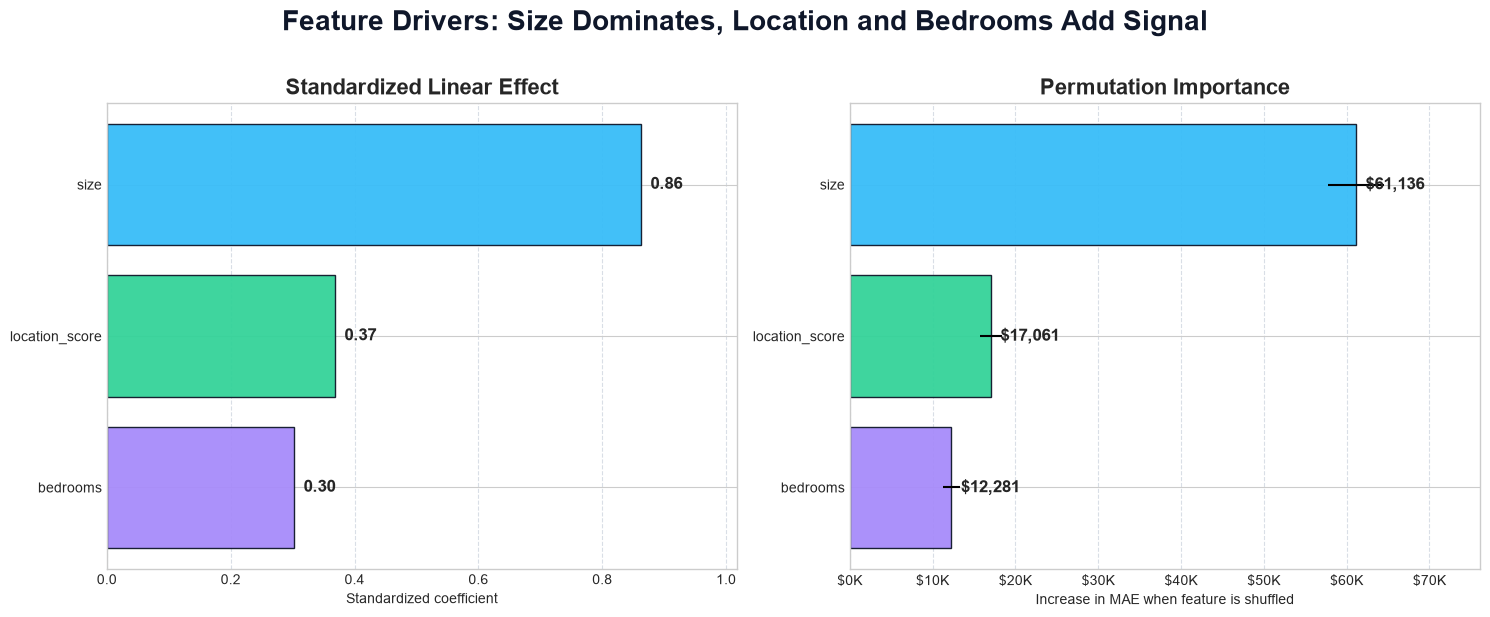

In [16]:
# Permutation importance plus combined feature-driver visualization
# 1.Tính Permutation Importance cho mô hình Random Forest để kiểm tra mỗi feature quan trọng như thế nào đối với khả năng dự đoán.
# 2.Vẽ biểu đồ kết hợp để so sánh ảnh hưởng tuyến tính của các features với mức độ quan trọng theo Permutation Importance.
perm_result = permutation_importance( #Tính Permutation Importance
    rf_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=SEED,
    scoring="neg_mean_absolute_error"
)

perm_importance = pd.DataFrame({ #Tạo bảng DataFrame để hiển thị mức độ quan trọng của từng feature dựa trên Permutation Importance.
    "feature": feature_names,
    "mean_mae_increase": perm_result.importances_mean,
    "std": perm_result.importances_std
}).sort_values("mean_mae_increase", ascending=False)

display(perm_importance)

feature_color_map = { #gắn màu sắc cho từng feature để biểu đồ trực quan hơn.
    "size": COLORS["blue"],
    "location_score": COLORS["teal"],
    "bedrooms": COLORS["purple"]
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

fig.suptitle(
    "Feature Drivers: Size Dominates, Location and Bedrooms Add Signal",
    fontsize=20,
    fontweight="bold",
    color=COLORS["dark"],
    y=1.02
)

# Standardized linear effect
linear_colors = [
    feature_color_map.get(feature, COLORS["gray"])
    for feature in linear_effect["feature"]
]

axes[0].barh(
    linear_effect["feature"],
    linear_effect["standardized_linear_effect"],
    color=linear_colors,
    edgecolor=COLORS["dark"],
    alpha=0.95
)

axes[0].invert_yaxis()
axes[0].set_title("Standardized Linear Effect", fontsize=16, fontweight="bold")
axes[0].set_xlabel("Standardized coefficient")

left_limit = linear_effect["standardized_linear_effect"].max() * 1.18
axes[0].set_xlim(0, left_limit)

for i, value in enumerate(linear_effect["standardized_linear_effect"]):
    axes[0].text(
        value + (left_limit * 0.015),
        i,
        f"{value:.2f}",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

# Permutation importance
perm_colors = [
    feature_color_map.get(feature, COLORS["gray"])
    for feature in perm_importance["feature"]
]

axes[1].barh(
    perm_importance["feature"],
    perm_importance["mean_mae_increase"],
    xerr=perm_importance["std"],
    color=perm_colors,
    edgecolor=COLORS["dark"],
    alpha=0.95
)

axes[1].invert_yaxis()
axes[1].set_title("Permutation Importance", fontsize=16, fontweight="bold")
axes[1].set_xlabel("Increase in MAE when feature is shuffled")
axes[1].xaxis.set_major_formatter(FuncFormatter(currency_k))

right_limit = (
    perm_importance["mean_mae_increase"] + perm_importance["std"]
).max() * 1.18

axes[1].set_xlim(0, right_limit)

for i, value in enumerate(perm_importance["mean_mae_increase"]):
    axes[1].text(
        value + (right_limit * 0.015),
        i,
        currency_full(value),
        va="center",
        fontsize=12,
        fontweight="bold"
    )

for ax in axes:
    ax.grid(True, axis="x", linestyle="--", alpha=0.35, color="#94A3B8")

plt.tight_layout()
save_figure(fig, "house_price_feature_drivers.png")
plt.show()
# Từ kết quả biểu đồ, nhóm rút ra:
# Diện tích nhà (size) là feature quan trọng nhất trong cả Linear Regression và Random Forest.
# location_score đứng thứ hai, cho thấy vị trí cũng cung cấp thông tin đáng kể cho dự đoán.
# bedrooms đứng thứ ba, nhưng không có nghĩa là số phòng ngủ không quan trọng.
# Hai phương pháp có cùng thứ tự feature importance, củng cố nhận định rằng diện tích là yếu tố nổi bật trong dataset này.


### Explainability Findings

The feature-importance results confirm the same pattern found during EDA.

Random Forest importance ranks the predictors as:

1. `size`: **0.816**
2. `location_score`: **0.112**
3. `bedrooms`: **0.072**

Permutation importance gives a more practical interpretation. When each feature is shuffled, model error increases by approximately:

- `size`: **$61,136**
- `location_score`: **$17,061**
- `bedrooms`: **$12,281**

This shows that `size` is the dominant driver of predicted price, while location score and bedrooms provide additional but smaller predictive value.


## 9. Summary

This project demonstrates an end-to-end house price prediction workflow using a neural network and two traditional machine-learning models.

The workflow includes data validation, exploratory data analysis, preprocessing, neural-network training, model benchmarking, residual diagnostics, and feature interpretation.

Three models are evaluated:

- Linear Regression
- Neural Network
- Random Forest

Linear Regression provides a simple baseline, while Random Forest provides a non-linear benchmark. The neural network is the primary deep-learning model.

The models are evaluated using MAE, RMSE, and R² on the same test set.

The benchmark results help determine whether the neural network provides meaningful predictive improvement over simpler alternatives.

Feature analysis is used to investigate the relative importance of property size, location score, and bedroom count.

The final conclusions are based on the actual evaluation results rather than assuming that the neural network must outperform the traditional models.

In [17]:
import sys

print(sys.executable)
print(sys.version)

d:\Intro_to_DL_BTL\house-price-prediction-main\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
